# 07 – Opdracht: Student Lifestyle Dataset
Analyse van `student_lifestyle_dataset.csv`: opschonen → univariaat → bivariaat → multivariaat → conclusie.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 1. Data verkennen en opschonen
### 1.1 Importeren en eerste blik

In [2]:
df_raw = pd.read_csv("../datasets/student_lifestyle_dataset.csv")
print(df_raw.shape)
df_raw.head()

(305, 15)


,student_id,age,gender,study_hours,sleep_hours,coffee_intake,grades,attendance_rate,stress_level,social_media_hours,part_time_job,major,weekly_exercise_hours,satisfaction_level,internet_usage_gb
0,S1000,23,Other,7.3,7.8,2,73.9,98.7,3,3.9,yes,Engineering,NaN,4,22.6
1,S1001,20,F,5.9,NaN,0,77.0,51.0,1,1.0,yes,Medicine,2.8,4,16.8
2,S1002,29,Female,2.7,8.1,1,NaN,86.9,3,2.6,Y,Medicine,1.9,10,2.3
3,S1003,27,Male,6.2,10.3,3,76.6,88.4,6,1.8,Y,Engineering,2.7,2,24.9
4,S1004,24,NaN,3.2,NaN,1,NaN,62.2,8,2.3,no,AI,1.5,1,18.7


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 305 entries, 0 to 304
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   student_id             305 non-null    str    
 1   age                    305 non-null    int64  
 2   gender                 280 non-null    str    
 3   study_hours            305 non-null    float64
 4   sleep_hours            290 non-null    float64
 5   coffee_intake          305 non-null    int64  
 6   grades                 290 non-null    float64
 7   attendance_rate        305 non-null    float64
 8   stress_level           305 non-null    int64  
 9   social_media_hours     290 non-null    float64
 10  part_time_job          305 non-null    str    
 11  major                  305 non-null    str    
 12  weekly_exercise_hours  290 non-null    float64
 13  satisfaction_level     305 non-null    int64  
 14  internet_usage_gb      305 non-null    float64
dtypes: float64(7), in

In [4]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
age,305.0,22.698361,4.840974,-1.0,20.00,23.00,26.000,29.0
study_hours,305.0,4.996721,2.114857,-1.7,3.60,5.10,6.500,9.3
sleep_hours,290.0,7.024138,2.035575,-2.0,6.00,7.10,8.200,11.8
coffee_intake,305.0,3.567213,2.255747,0.0,2.00,4.00,5.000,7.0
grades,290.0,71.391379,16.115381,30.9,60.75,70.95,82.975,116.6
attendance_rate,305.0,74.319672,14.378877,50.0,61.40,74.80,87.100,99.6
stress_level,305.0,5.511475,2.852867,1.0,3.00,5.00,8.000,10.0
social_media_hours,290.0,3.098966,1.986764,-2.3,1.80,3.10,4.400,8.3
weekly_exercise_hours,290.0,2.024483,1.488196,-3.1,1.10,2.10,3.000,5.4
satisfaction_level,305.0,5.639344,2.802917,1.0,3.00,6.00,8.000,10.0


### 1.2 Missende waarden

In [5]:
missing = df_raw.isna().sum()
missing[missing > 0].sort_values(ascending=False)

gender                   25
sleep_hours              15
grades                   15
social_media_hours       15
weekly_exercise_hours    15
dtype: int64

### 1.3 Duplicaten

In [6]:
print("Volledig identieke rijen:", df_raw.duplicated().sum())
print("Dubbele student_id's:   ", df_raw["student_id"].duplicated().sum())
df_raw[df_raw["student_id"].duplicated(keep=False)].sort_values("student_id")

Volledig identieke rijen: 5
Dubbele student_id's:    5


,student_id,age,gender,study_hours,sleep_hours,coffee_intake,grades,attendance_rate,stress_level,social_media_hours,part_time_job,major,weekly_exercise_hours,satisfaction_level,internet_usage_gb
106,S1106,29,male,2.3,9.4,1,102.8,98.2,10,2.1,No,Art,1.8,1,12.2
304,S1106,29,male,2.3,9.4,1,102.8,98.2,10,2.1,No,Art,1.8,1,12.2
123,S1123,17,Female,8.1,8.5,3,56.6,82.3,5,4.2,N,Art,5.2,3,19.7
301,S1123,17,Female,8.1,8.5,3,56.6,82.3,5,4.2,N,Art,5.2,3,19.7
185,S1185,21,F,8.3,6.7,6,70.9,62.8,1,5.4,Yes,Engineering,3.2,6,16.9
302,S1185,21,F,8.3,6.7,6,70.9,62.8,1,5.4,Yes,Engineering,3.2,6,16.9
189,S1189,28,F,5.7,9.3,3,45.5,73.9,3,3.3,yes,Art,2.2,2,12.9
300,S1189,28,F,5.7,9.3,3,45.5,73.9,3,3.3,yes,Art,2.2,2,12.9
213,S1213,17,male,8.2,8.4,0,69.0,99.6,7,3.2,Yes,AI,1.4,9,11.7
303,S1213,17,male,8.2,8.4,0,69.0,99.6,7,3.2,Yes,AI,1.4,9,11.7


### 1.4 Inconsistente categorieën

In [7]:
for col in ["gender", "part_time_job", "major"]:
    print(df_raw[col].value_counts(dropna=False), "\n")

gender
F         48
female    44
Female    42
Male      40
male      40
Other     33
M         33
NaN       25
Name: count, dtype: int64 

part_time_job
Yes    59
N      59
yes    52
No     50
Y      43
no     42
Name: count, dtype: int64 

major
Art            57
Psychology     49
Medicine       48
AI             48
Engineering    47
Business       46
Unknown        10
Name: count, dtype: int64 



### 1.5 Onmogelijke waarden

In [8]:
num_cols = ["age", "study_hours", "sleep_hours", "grades", "attendance_rate",
            "social_media_hours", "weekly_exercise_hours", "internet_usage_gb"]
checks = {
    "age < 15":                   (df_raw["age"] < 15).sum(),
    "study_hours < 0":            (df_raw["study_hours"] < 0).sum(),
    "sleep_hours < 0":            (df_raw["sleep_hours"] < 0).sum(),
    "grades > 100":               (df_raw["grades"] > 100).sum(),
    "social_media_hours < 0":     (df_raw["social_media_hours"] < 0).sum(),
    "weekly_exercise_hours < 0":  (df_raw["weekly_exercise_hours"] < 0).sum(),
    "attendance_rate > 100":      (df_raw["attendance_rate"] > 100).sum(),
    "stress_level buiten 1-10":   (~df_raw["stress_level"].between(1, 10)).sum(),
    "satisfaction buiten 1-10":   (~df_raw["satisfaction_level"].between(1, 10)).sum(),
}
pd.Series(checks, name="aantal rijen")

age < 15                      5
study_hours < 0               2
sleep_hours < 0               5
grades > 100                 10
social_media_hours < 0       15
weekly_exercise_hours < 0    24
attendance_rate > 100         0
stress_level buiten 1-10      0
satisfaction buiten 1-10      0
Name: aantal rijen, dtype: int64

### 1.6 Opschonen

In [9]:
df = df_raw.copy()
n_start = len(df)

# 1. Duplicaten verwijderen (identieke rijen met dezelfde student_id)
df = df.drop_duplicates()

# 2. Categorieën standaardiseren
gender_map = {"m": "Male", "male": "Male", "f": "Female", "female": "Female", "other": "Other"}
df["gender"] = df["gender"].str.strip().str.lower().map(gender_map).fillna("Unknown")

job_map = {"y": "Yes", "yes": "Yes", "n": "No", "no": "No"}
df["part_time_job"] = df["part_time_job"].str.strip().str.lower().map(job_map)

# 3. Onmogelijke waarden -> NaN (ze zijn fout, niet extreem)
df.loc[df["age"] < 15, "age"] = np.nan
df.loc[df["grades"] > 100, "grades"] = np.nan
for col in ["study_hours", "sleep_hours", "social_media_hours", "weekly_exercise_hours"]:
    df.loc[df[col] < 0, col] = np.nan

# 4. Missende numerieke waarden imputeren met de mediaan (robuust tegen outliers)
impute_cols = ["age", "study_hours", "sleep_hours", "grades",
               "social_media_hours", "weekly_exercise_hours"]
for col in impute_cols:
    df[col] = df[col].fillna(df[col].median())

df["age"] = df["age"].astype(int)
for col in ["gender", "part_time_job", "major"]:
    df[col] = df[col].astype("category")

print(f"Rijen: {n_start} -> {len(df)}")
print("Resterende NaN's:", df.isna().sum().sum())
df.describe().T

Rijen: 305 -> 300
Resterende NaN's: 0


,count,mean,std,min,25%,50%,75%,max
age,300.0,23.103333,3.717354,17.0,20.000,23.00,26.00,29.0
study_hours,300.0,5.011667,2.044005,0.1,3.600,5.10,6.50,9.3
sleep_hours,300.0,7.155667,1.605009,2.8,6.100,7.10,8.20,11.8
coffee_intake,300.0,3.583333,2.255366,0.0,2.000,4.00,5.25,7.0
grades,300.0,70.313000,14.336792,30.9,61.175,70.65,80.05,99.6
attendance_rate,300.0,74.169000,14.334735,50.0,61.300,74.60,87.10,99.6
stress_level,300.0,5.516667,2.847822,1.0,3.000,5.00,8.00,10.0
social_media_hours,300.0,3.301333,1.704666,0.1,2.200,3.20,4.30,8.3
weekly_exercise_hours,300.0,2.270333,1.143406,-0.0,1.500,2.20,2.90,5.4
satisfaction_level,300.0,5.663333,2.794522,1.0,3.000,6.00,8.00,10.0


### 1.7 Documentatie opschoonkeuzes

| Probleem | Aantal | Actie | Reden |
|---|---|---|---|
| Identieke duplicaten (S1106, S1123, S1185, S1189, S1213) | 5 | Verwijderd | Zelfde student telt anders dubbel mee |
| `gender` in 8 schrijfwijzen (M/male/Male, F/female/Female, NA, leeg) | — | Gemapt naar Male/Female/Other/Unknown | Eén categorie per groep; ontbrekend apart houden i.p.v. raden |
| `part_time_job` als Y/yes/Yes/N/no/No | — | Gemapt naar Yes/No | Zelfde betekenis, andere notatie |
| `age = -1` | 5 | NaN → mediaan | Onmogelijke leeftijd, waarschijnlijk placeholder |
| `grades > 100` | 10 | NaN → mediaan | Buiten schaal 0–100 |
| Negatieve uren (`study`, `sleep = -2.0`, `social_media`, `exercise`) | zie 1.5 | NaN → mediaan | Uren kunnen niet negatief zijn |
| Missende waarden (`grades`, `sleep_hours`, `social_media_hours`, `weekly_exercise_hours`) | zie 1.2 | Mediaan | Dataset is klein; rijen verwijderen kost te veel data. Mediaan is robuust tegen outliers |
| `major = Unknown` | — | Behouden als eigen categorie | Geen betrouwbare manier om in te vullen |

**Let op:** mediaan-imputatie trekt de verdeling naar het midden en verzwakt correlaties licht. Dit noemen we bij de beperkingen.

## 2. Univariate analyse
*TODO: histogrammen + boxplots voor numerieke variabelen, bar charts voor categorische. Benoem scheefheid en IQR-outliers.*

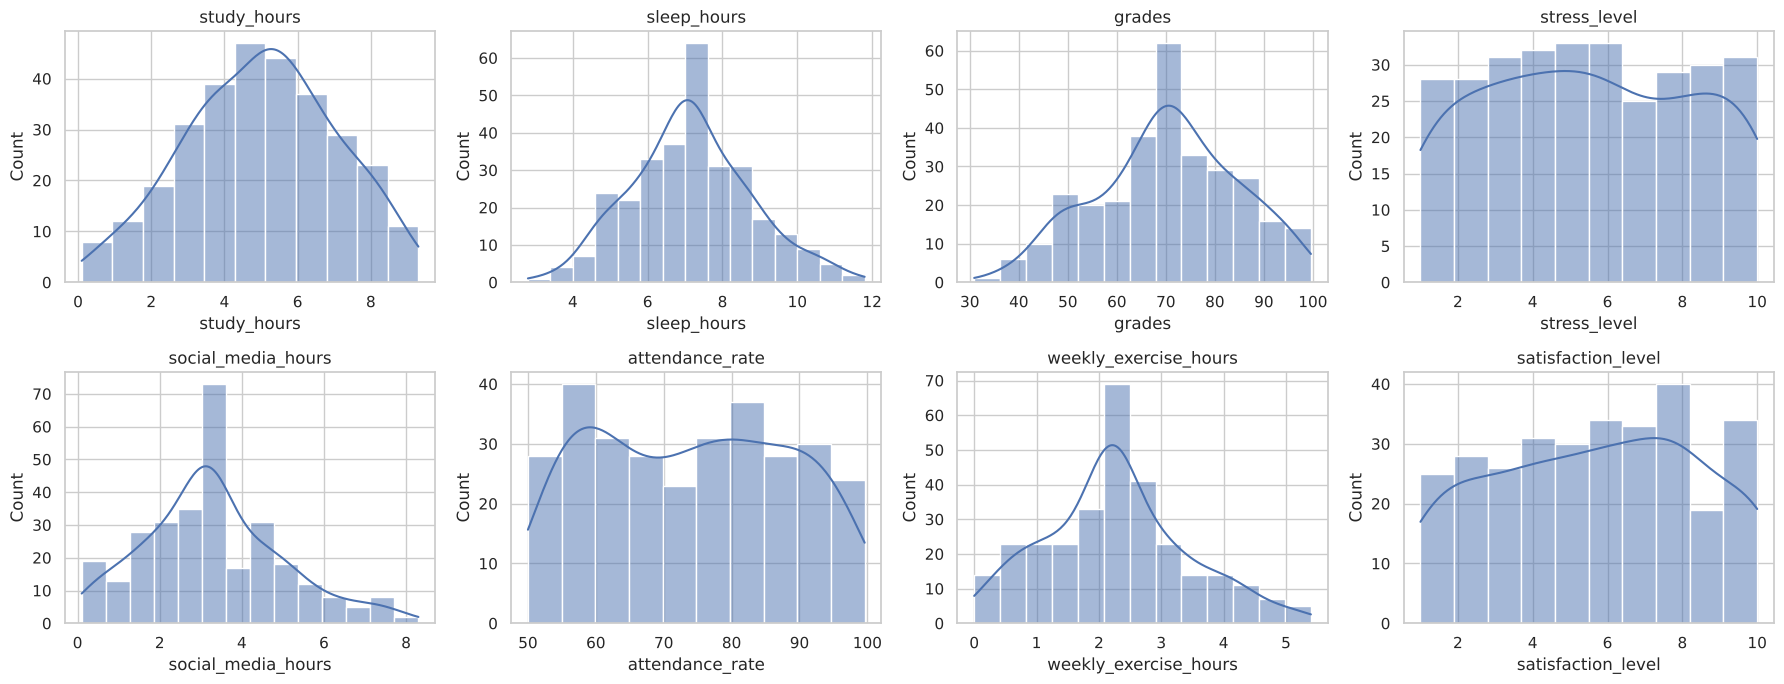

In [10]:
num = ["study_hours", "sleep_hours", "grades", "stress_level", "social_media_hours",
       "attendance_rate", "weekly_exercise_hours", "satisfaction_level"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.flat, num):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()

## 3. Bivariate analyse
*TODO: scatterplots met regressielijn, Pearson/Spearman, boxplots categorisch × numeriek.*

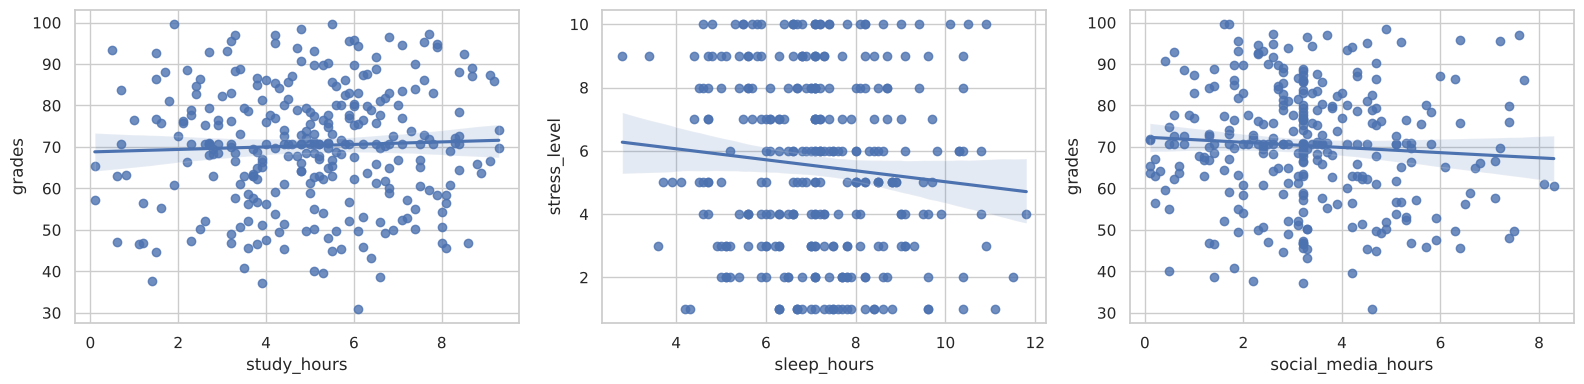

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.regplot(data=df, x="study_hours", y="grades", ax=axes[0])
sns.regplot(data=df, x="sleep_hours", y="stress_level", ax=axes[1])
sns.regplot(data=df, x="social_media_hours", y="grades", ax=axes[2])
plt.tight_layout()

## 4. Multivariate analyse
*TODO: heatmap, pairplot, meervoudige regressie (statsmodels), KMeans-clustering.*

Text(0.5, 1.0, 'Correlatiematrix')

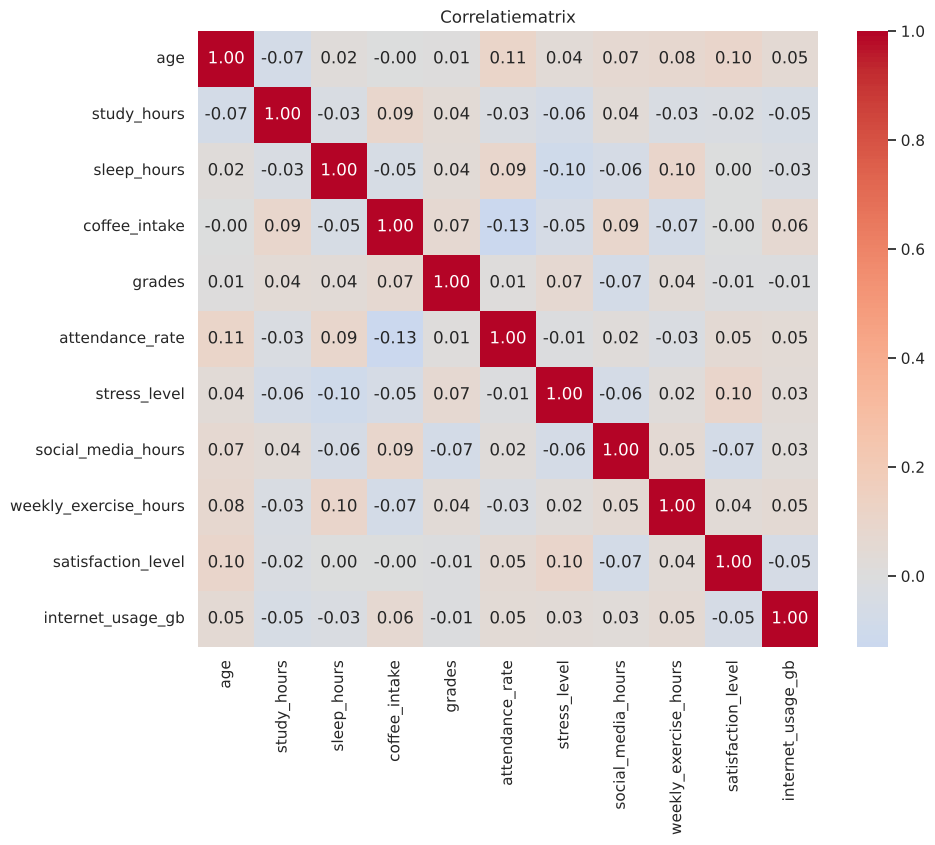

In [12]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlatiematrix")

## 5. Conclusie
*TODO: belangrijkste bevindingen, wat de data wel/niet laat zien, beperkingen.*